In [16]:
%matplotlib inline

/home/locolinux2/miniconda3/envs/U24/lib/python3.9/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 6 x 4 in image.
/home/locolinux2/miniconda3/envs/U24/lib/python3.9/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: guidance_scale_3.pdf
/home/locolinux2/miniconda3/envs/U24/lib/python3.9/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 6 x 4 in image.
/home/locolinux2/miniconda3/envs/U24/lib/python3.9/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: guidance_scale_5.pdf
/tmp/ipykernel_14669/878281806.py:76: FutureWarning: Using print(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


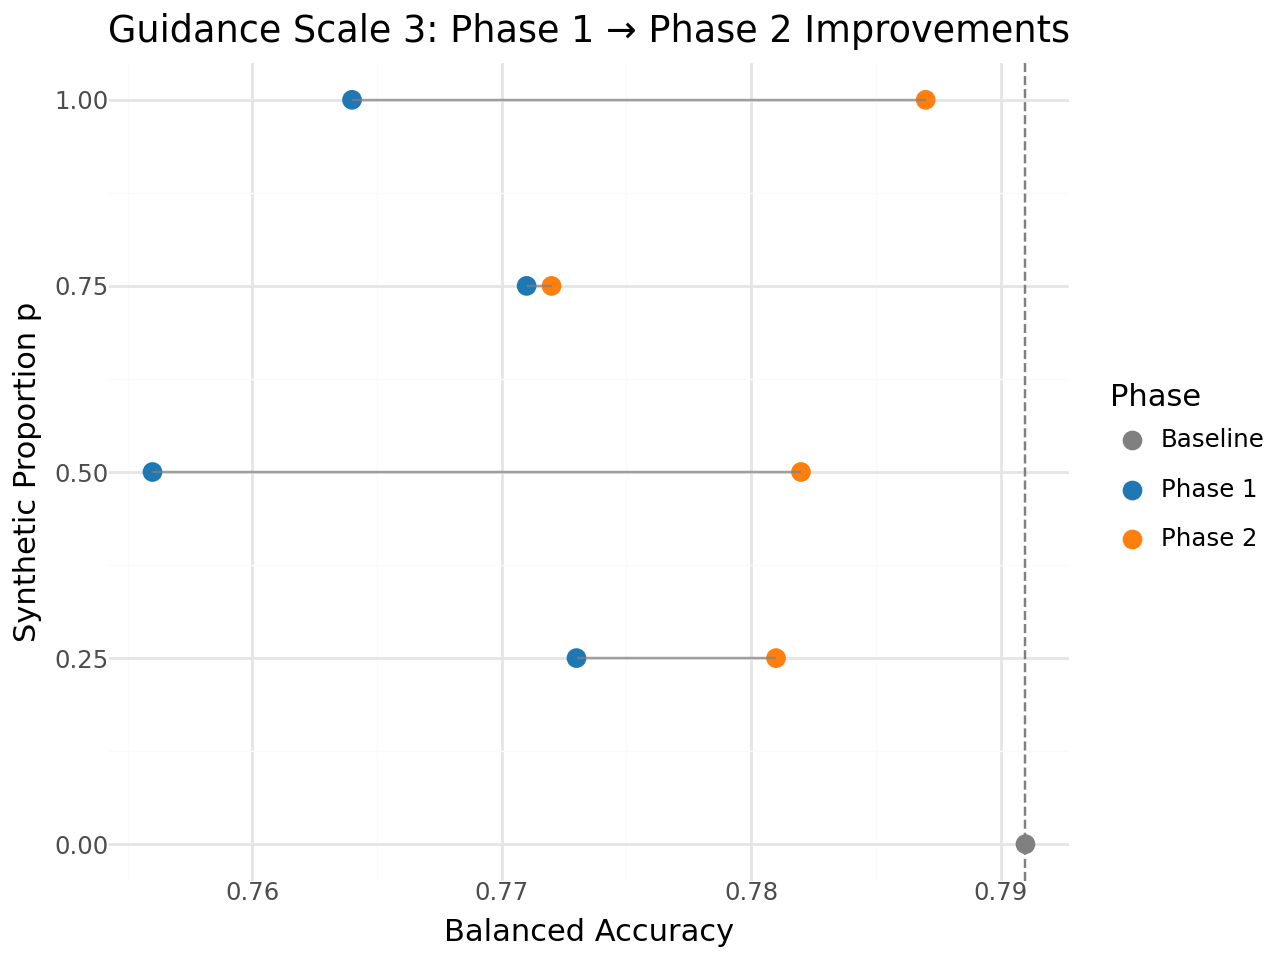

/tmp/ipykernel_14669/878281806.py:77: FutureWarning: Using print(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


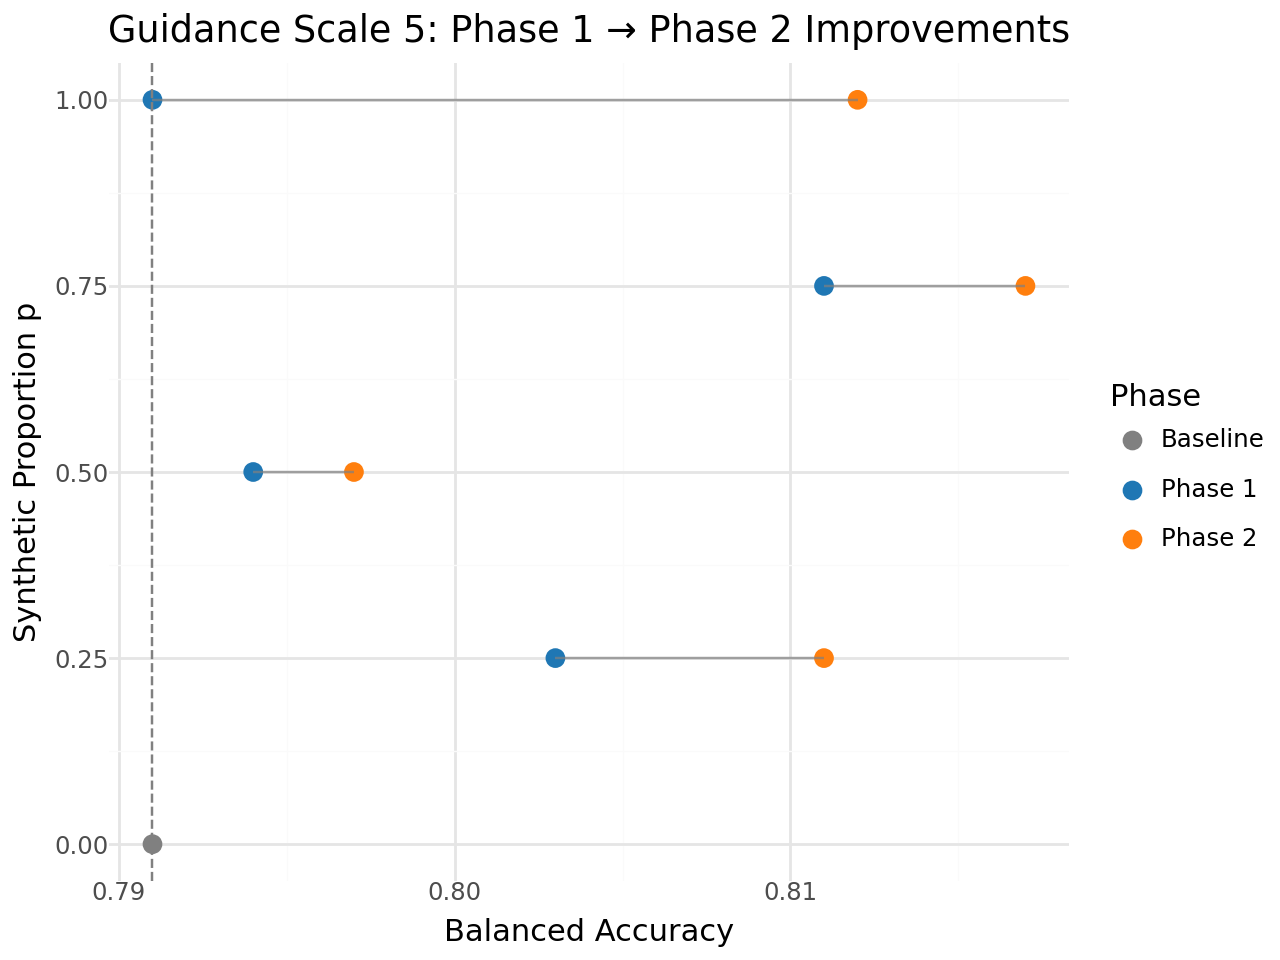

In [1]:
import pandas as pd
from plotnine import (
    ggplot, aes, geom_point, geom_segment, labs, theme_minimal,
    scale_color_manual, geom_vline
)

# Data including baseline (p=0)
data = [
    [3, 0.0, "Baseline", 0.791],
    [5, 0.0, "Baseline", 0.791],

    # G.Scale 3
    [3, 0.25, "Phase 1", 0.773],
    [3, 0.25, "Phase 2", 0.781],
    [3, 0.50, "Phase 1", 0.756],
    [3, 0.50, "Phase 2", 0.782],
    [3, 0.75, "Phase 1", 0.771],
    [3, 0.75, "Phase 2", 0.772],
    [3, 1.0,  "Phase 1", 0.764],
    [3, 1.0,  "Phase 2", 0.787],

    # G.Scale 5
    [5, 0.25, "Phase 1", 0.803],
    [5, 0.25, "Phase 2", 0.811],
    [5, 0.50, "Phase 1", 0.794],
    [5, 0.50, "Phase 2", 0.797],
    [5, 0.75, "Phase 1", 0.811],
    [5, 0.75, "Phase 2", 0.817],
    [5, 1.0,  "Phase 1", 0.791],
    [5, 1.0,  "Phase 2", 0.812],
]

df = pd.DataFrame(data, columns=["GScale", "p", "Phase", "BA"])

# Create line segments (only Phase 1→2, not baseline)
df_segments = (
    df[df["Phase"].isin(["Phase 1","Phase 2"])]
    .pivot(index=["GScale","p"], columns="Phase", values="BA")
    .reset_index()
)

# Colors
colors = {"Baseline": "gray", "Phase 1": "#1f77b4", "Phase 2": "#ff7f0e"}
baseline_value = 0.791

def make_plot(scale):
    df_sub = df[df["GScale"] == scale]
    df_seg_sub = df_segments[df_segments["GScale"] == scale]

    plot = (
        ggplot(df_sub, aes(x="BA", y="p", color="Phase"))
        + geom_point(size=3)
        + geom_segment(
            df_seg_sub,
            aes(x="Phase 1", xend="Phase 2", y="p", yend="p"),
            color="gray", alpha=0.7
        )
        + geom_vline(xintercept=baseline_value, linetype="dashed", color="gray")
        + scale_color_manual(values=colors)
        + labs(
            title=f"Guidance Scale {scale}: Phase 1 → Phase 2 Improvements",
            x="Balanced Accuracy",
            y="Synthetic Proportion p"
        )
        + theme_minimal()
    )
    return plot

# Generate plots
plot_g3 = make_plot(3)
plot_g5 = make_plot(5)

# Save as PDFs
plot_g3.save("guidance_scale_3.pdf", width=6, height=4)
plot_g5.save("guidance_scale_5.pdf", width=6, height=4)
print(plot_g3)
print(plot_g5)



/home/locolinux2/miniconda3/envs/U24/lib/python3.9/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 7 x 4.5 in image.
/home/locolinux2/miniconda3/envs/U24/lib/python3.9/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: guidance_combined.pdf
/tmp/ipykernel_14669/2963880251.py:91: FutureWarning: Using print(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


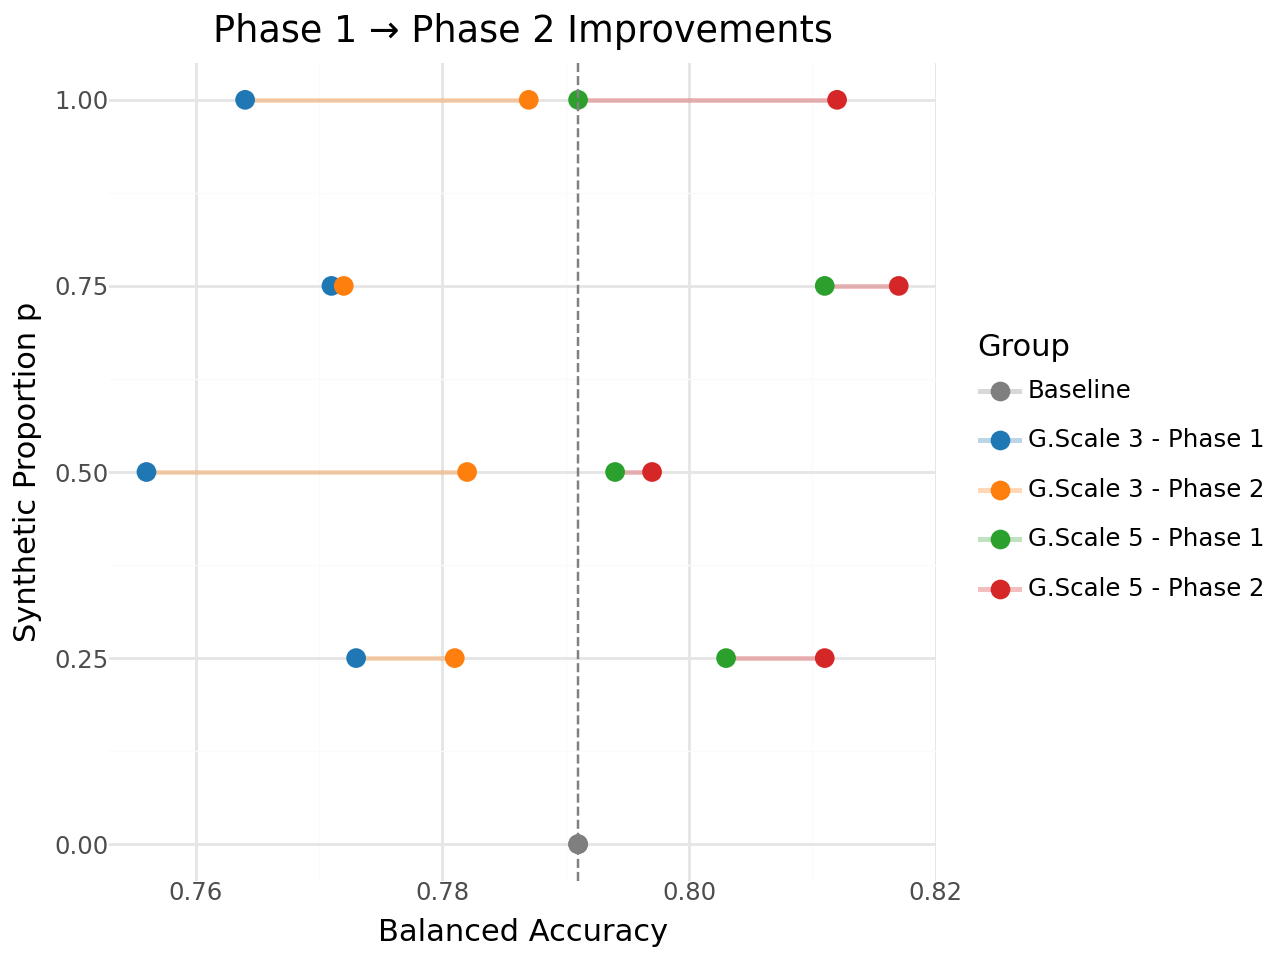

In [2]:
import pandas as pd
from plotnine import (
    ggplot, aes, geom_point, geom_segment, labs, theme_minimal,
    scale_color_manual, geom_vline
)

# Data including baseline (p=0)
data = [
    [3, 0.0, "Baseline", 0.791],
    [5, 0.0, "Baseline", 0.791],

    # G.Scale 3
    [3, 0.25, "Phase 1", 0.773],
    [3, 0.25, "Phase 2", 0.781],
    [3, 0.50, "Phase 1", 0.756],
    [3, 0.50, "Phase 2", 0.782],
    [3, 0.75, "Phase 1", 0.771],
    [3, 0.75, "Phase 2", 0.772],
    [3, 1.0,  "Phase 1", 0.764],
    [3, 1.0,  "Phase 2", 0.787],

    # G.Scale 5
    [5, 0.25, "Phase 1", 0.803],
    [5, 0.25, "Phase 2", 0.811],
    [5, 0.50, "Phase 1", 0.794],
    [5, 0.50, "Phase 2", 0.797],
    [5, 0.75, "Phase 1", 0.811],
    [5, 0.75, "Phase 2", 0.817],
    [5, 1.0,  "Phase 1", 0.791],
    [5, 1.0,  "Phase 2", 0.812],
]

df = pd.DataFrame(data, columns=["GScale", "p", "Phase", "BA"])

# Build new legend labels
def label_row(r):
    if r["Phase"] == "Baseline":
        return "Baseline"
    return f'G.Scale {int(r["GScale"])} - {r["Phase"]}'

df["Group"] = df.apply(label_row, axis=1)

# Segments connecting Phase 1 → Phase 2
df_segments = (
    df[df["Phase"].isin(["Phase 1", "Phase 2"])]
    .pivot(index=["GScale", "p"], columns="Phase", values="BA")
    .reset_index()
)
df_segments["Group"] = df_segments["GScale"].map({
    3: "G.Scale 3 - Phase 2",
    5: "G.Scale 5 - Phase 2"
})

# Legend order & colors
legend_order = [
    "Baseline",
    "G.Scale 3 - Phase 1", "G.Scale 3 - Phase 2",
    "G.Scale 5 - Phase 1", "G.Scale 5 - Phase 2",
]
color_list = [
    "#7f7f7f",   # Baseline
    "#1f77b4",   # G.Scale 3 - Phase 1
    "#ff7f0e",   # G.Scale 3 - Phase 2
    "#2ca02c",   # G.Scale 5 - Phase 1
    "#d62728",   # G.Scale 5 - Phase 2
]

baseline_value = 0.791

combined_plot = (
    ggplot(df, aes(x="BA", y="p", color="Group"))
    + geom_segment(
        df_segments,
        aes(x="Phase 1", xend="Phase 2", y="p", yend="p", color="Group"),
        alpha=0.3, size=1
    )
    + geom_point(size=3)
    + geom_vline(xintercept=baseline_value, linetype="dashed", color="gray")
    + scale_color_manual(values=color_list, limits=legend_order, name="")
    + labs(
        title="Phase 1 → Phase 2 Improvements",
        x="Balanced Accuracy",
        y="Synthetic Proportion p"
    )
    + theme_minimal()
)

# Save as PDF
combined_plot.save("guidance_combined.pdf", width=7, height=4.5)

print(combined_plot)


In [3]:
# Monochrome plot using shapes (no color), generated with matplotlib.
# This creates a PDF: /mnt/data/guidance_combined_monochrome.pdf

import pandas as pd
import matplotlib.pyplot as plt

# Data including baseline (p=0)
data = [
    [3, 0.0, "Baseline", 0.791],
    [5, 0.0, "Baseline", 0.791],

    # G.Scale 3
    [3, 0.25, "Phase 1", 0.773],
    [3, 0.25, "Phase 2", 0.781],
    [3, 0.50, "Phase 1", 0.756],
    [3, 0.50, "Phase 2", 0.782],
    [3, 0.75, "Phase 1", 0.771],
    [3, 0.75, "Phase 2", 0.772],
    [3, 1.0,  "Phase 1", 0.764],
    [3, 1.0,  "Phase 2", 0.787],

    # G.Scale 5
    [5, 0.25, "Phase 1", 0.803],
    [5, 0.25, "Phase 2", 0.811],
    [5, 0.50, "Phase 1", 0.794],
    [5, 0.50, "Phase 2", 0.797],
    [5, 0.75, "Phase 1", 0.811],
    [5, 0.75, "Phase 2", 0.817],
    [5, 1.0,  "Phase 1", 0.791],
    [5, 1.0,  "Phase 2", 0.812],
]

df = pd.DataFrame(data, columns=["GScale", "p", "Phase", "BA"])

# Build new legend labels
def label_row(r):
    if r["Phase"] == "Baseline":
        return "Baseline"
    return f'G.Scale {int(r["GScale"])} - {r["Phase"]}'

df["Group"] = df.apply(label_row, axis=1)

# Segments connecting Phase 1 → Phase 2
df_segments = (
    df[df["Phase"].isin(["Phase 1", "Phase 2"])]
    .pivot(index=["GScale", "p"], columns="Phase", values="BA")
    .reset_index()
)

# Marker shapes (monochrome), distinct by Group
marker_map = {
    "Baseline": "s",                # square
    "G.Scale 3 - Phase 1": "^",     # triangle up
    "G.Scale 3 - Phase 2": "v",     # triangle down
    "G.Scale 5 - Phase 1": "o",     # circle
    "G.Scale 5 - Phase 2": "D",     # diamond
}

# Linestyle by G.Scale (still monochrome)
linestyle_map = {3: "-", 5: (0, (3, 3))}  # solid for 3, dashed for 5

baseline_value = 0.791

# Start plotting
fig, ax = plt.subplots(figsize=(7, 4.5))

# Plot segments (Phase 1 → Phase 2) for each (GScale, p)
for _, row in df_segments.iterrows():
    gs = int(row["GScale"])
    y = row["p"]
    x1 = row["Phase 1"]
    x2 = row["Phase 2"]
    ax.hlines(y, xmin=x1, xmax=x2, linestyles=linestyle_map.get(gs, "-"), colors="black", linewidth=1, alpha=0.5)

# Plot points with distinct marker shapes, monochrome outlines
for group, sub in df.groupby("Group"):
    ax.scatter(
        sub["BA"], sub["p"],
        marker=marker_map.get(group, "o"),
        facecolors="none", edgecolors="black", linewidths=1.2, s=60,
        label=group
    )

# Vertical line at baseline BA
ax.axvline(baseline_value, linestyle="--", color="black", linewidth=1)

# Labels and title
ax.set_title("Phase 1 → Phase 2 Improvements", fontsize=12)
ax.set_xlabel("Balanced Accuracy")
ax.set_ylabel("AI-generated Proportion p")

# Legend (single, monochrome)
handles, labels = ax.get_legend_handles_labels()
# order legend items
legend_order = [
    "Baseline",
    "G.Scale 3 - Phase 1", "G.Scale 3 - Phase 2",
    "G.Scale 5 - Phase 1", "G.Scale 5 - Phase 2",
]
order_idx = [labels.index(l) for l in legend_order if l in labels]
ordered_handles = [handles[i] for i in order_idx]
ordered_labels = [labels[i] for i in order_idx]

ax.legend(
    ordered_handles, ordered_labels,
    title="", frameon=False, loc="lower left", fontsize=9
)


ax.grid(True, linewidth=0.5, alpha=0.3)

fig.tight_layout()
out_path = "guidance_combined_monochrome.pdf"
fig.savefig(out_path, bbox_inches="tight")

out_path


'guidance_combined_monochrome.pdf'

'guidance_combined_allblue.pdf'

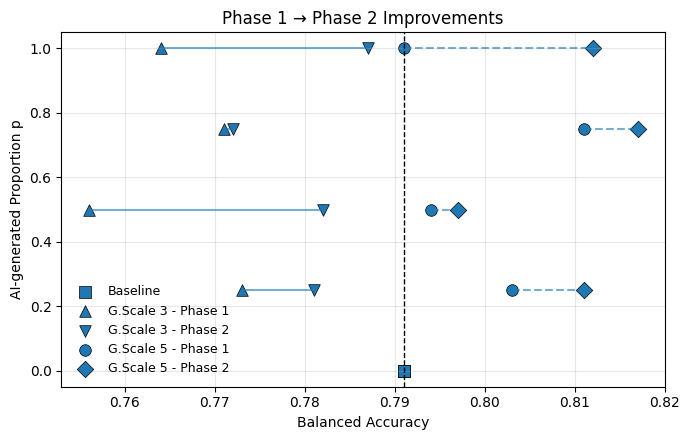

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Data including baseline (p=0)
data = [
    [3, 0.0, "Baseline", 0.791],
    [5, 0.0, "Baseline", 0.791],

    # G.Scale 3
    [3, 0.25, "Phase 1", 0.773],
    [3, 0.25, "Phase 2", 0.781],
    [3, 0.50, "Phase 1", 0.756],
    [3, 0.50, "Phase 2", 0.782],
    [3, 0.75, "Phase 1", 0.771],
    [3, 0.75, "Phase 2", 0.772],
    [3, 1.0,  "Phase 1", 0.764],
    [3, 1.0,  "Phase 2", 0.787],

    # G.Scale 5
    [5, 0.25, "Phase 1", 0.803],
    [5, 0.25, "Phase 2", 0.811],
    [5, 0.50, "Phase 1", 0.794],
    [5, 0.50, "Phase 2", 0.797],
    [5, 0.75, "Phase 1", 0.811],
    [5, 0.75, "Phase 2", 0.817],
    [5, 1.0,  "Phase 1", 0.791],
    [5, 1.0,  "Phase 2", 0.812],
]

df = pd.DataFrame(data, columns=["GScale", "p", "Phase", "BA"])

def label_row(r):
    if r["Phase"] == "Baseline":
        return "Baseline"
    return f'G.Scale {int(r["GScale"])} - {r["Phase"]}'

df["Group"] = df.apply(label_row, axis=1)

df_segments = (
    df[df["Phase"].isin(["Phase 1", "Phase 2"])]
    .pivot(index=["GScale", "p"], columns="Phase", values="BA")
    .reset_index()
)

# --- ALL BLUE ---
COLOR = "#1f77b4"

marker_map = {
    "Baseline": "s",
    "G.Scale 3 - Phase 1": "^",
    "G.Scale 3 - Phase 2": "v",
    "G.Scale 5 - Phase 1": "o",
    "G.Scale 5 - Phase 2": "D",
}

linestyle_map = {3: "-", 5: "--"}
baseline_value = 0.791

fig, ax = plt.subplots(figsize=(7, 4.5))

# Plot segments (all same color, linestyle distinguishes G.Scale)
for _, row in df_segments.iterrows():
    gs = int(row["GScale"])
    y = row["p"]
    x1 = row["Phase 1"]
    x2 = row["Phase 2"]

    ax.hlines(
        y=y,
        xmin=x1,
        xmax=x2,
        colors=COLOR,
        linestyles=linestyle_map.get(gs, "-"),
        linewidth=1.5,
        alpha=0.6
    )

# Plot points (all same color)
for group, sub in df.groupby("Group"):
    ax.scatter(
        sub["BA"],
        sub["p"],
        color=COLOR,
        marker=marker_map[group],
        s=70,
        edgecolors="black",
        linewidths=0.5,
        label=group
    )

# Baseline line (also blue now)
ax.axvline(baseline_value, linestyle="--", color="black", linewidth=1)
ax.set_title("Phase 1 → Phase 2 Improvements", fontsize=12)
ax.set_xlabel("Balanced Accuracy")
ax.set_ylabel("AI-generated Proportion p")

handles, labels = ax.get_legend_handles_labels()
legend_order = [
    "Baseline",
    "G.Scale 3 - Phase 1", "G.Scale 3 - Phase 2",
    "G.Scale 5 - Phase 1", "G.Scale 5 - Phase 2",
]
order_idx = [labels.index(l) for l in legend_order if l in labels]

ax.legend(
    [handles[i] for i in order_idx],
    [labels[i] for i in order_idx],
    frameon=False,
    loc="lower left",
    fontsize=9
)

ax.grid(True, alpha=0.3)

fig.tight_layout()
out_path = "guidance_combined_allblue.pdf"
fig.savefig(out_path, bbox_inches="tight")

out_path

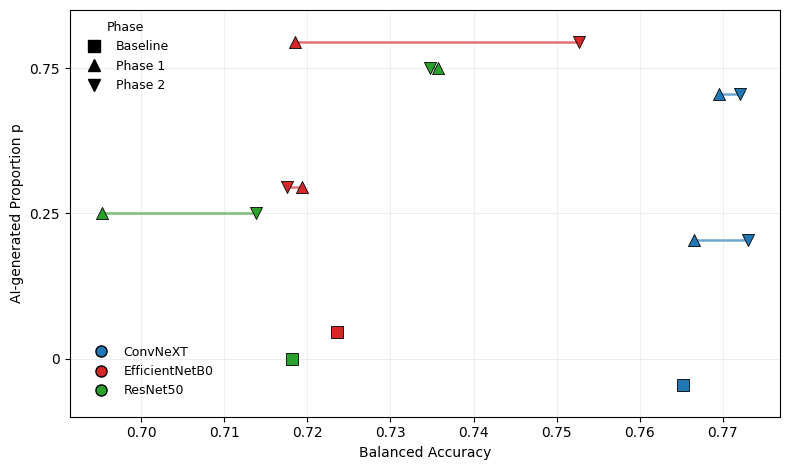

'baseline_vs_gscale5_balanced_accuracy_bucketed.pdf'

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Data: Baseline vs G.Scale 5 only
# p = 0.25 -> syn025
# p = 0.75 -> syn075
data = [
    # convnext_tiny
    ["convnext_tiny", 0.00, "Baseline", 0.7652],
    ["convnext_tiny", 0.25, "Phase 1", 0.7665],
    ["convnext_tiny", 0.25, "Phase 2", 0.7730],
    ["convnext_tiny", 0.75, "Phase 1", 0.7696],
    ["convnext_tiny", 0.75, "Phase 2", 0.7721],

    # efficientnet_b0
    ["efficientnet_b0", 0.00, "Baseline", 0.7236],
    ["efficientnet_b0", 0.25, "Phase 1", 0.7194],
    ["efficientnet_b0", 0.25, "Phase 2", 0.7176],
    ["efficientnet_b0", 0.75, "Phase 1", 0.7185],
    ["efficientnet_b0", 0.75, "Phase 2", 0.7527],

    # resnet50
    ["resnet50", 0.00, "Baseline", 0.7181],
    ["resnet50", 0.25, "Phase 1", 0.6953],
    ["resnet50", 0.25, "Phase 2", 0.7138],
    ["resnet50", 0.75, "Phase 1", 0.7357],
    ["resnet50", 0.75, "Phase 2", 0.7348],
]

df = pd.DataFrame(data, columns=["Model", "p", "Phase", "BA"])

model_order = ["convnext_tiny", "resnet50", "efficientnet_b0"]  # draw bottom -> top

color_map = {
    "convnext_tiny": "#1f77b4",    # blue
    "efficientnet_b0": "#d62728",  # red
    "resnet50": "#2ca02c",         # green
}

marker_map = {
    "Baseline": "s",
    "Phase 1": "^",
    "Phase 2": "v",
}

# Bucket centers for the three rows
bucket_y = {
    0.00: 0.0,   # Baseline
    0.25: 1.0,   # syn025
    0.75: 2.0,   # syn075
}

# Small vertical offsets within each bucket
# red topmost, green middle, blue bottom
model_offset = {
    "efficientnet_b0": 0.18,   # red
    "resnet50": 0.00,          # green
    "convnext_tiny": -0.18,    # blue
}

fig, ax = plt.subplots(figsize=(8, 4.8))

for model in model_order:
    sub = df[df["Model"] == model]

    y0 = bucket_y[0.00] + model_offset[model]
    y025 = bucket_y[0.25] + model_offset[model]
    y075 = bucket_y[0.75] + model_offset[model]

    # Baseline
    base = sub[sub["Phase"] == "Baseline"].iloc[0]
    ax.scatter(
        base["BA"], y0,
        s=80,
        marker=marker_map["Baseline"],
        facecolors=color_map[model],
        edgecolors="black",
        linewidths=0.6,
        zorder=3
    )

    # syn025
    p025 = sub[sub["p"] == 0.25].set_index("Phase")
    ax.hlines(
        y=y025,
        xmin=p025.loc["Phase 1", "BA"],
        xmax=p025.loc["Phase 2", "BA"],
        colors=color_map[model],
        linestyles="-",
        linewidth=1.8,
        alpha=0.65,
        zorder=1
    )
    ax.scatter(
        p025.loc["Phase 1", "BA"], y025,
        s=75,
        marker=marker_map["Phase 1"],
        facecolors=color_map[model],
        edgecolors="black",
        linewidths=0.6,
        zorder=3
    )
    ax.scatter(
        p025.loc["Phase 2", "BA"], y025,
        s=75,
        marker=marker_map["Phase 2"],
        facecolors=color_map[model],
        edgecolors="black",
        linewidths=0.6,
        zorder=3
    )

    # syn075
    p075 = sub[sub["p"] == 0.75].set_index("Phase")
    ax.hlines(
        y=y075,
        xmin=p075.loc["Phase 1", "BA"],
        xmax=p075.loc["Phase 2", "BA"],
        colors=color_map[model],
        linestyles="-",
        linewidth=1.8,
        alpha=0.65,
        zorder=1
    )
    ax.scatter(
        p075.loc["Phase 1", "BA"], y075,
        s=75,
        marker=marker_map["Phase 1"],
        facecolors=color_map[model],
        edgecolors="black",
        linewidths=0.6,
        zorder=3
    )
    ax.scatter(
        p075.loc["Phase 2", "BA"], y075,
        s=75,
        marker=marker_map["Phase 2"],
        facecolors=color_map[model],
        edgecolors="black",
        linewidths=0.6,
        zorder=3
    )

# ax.set_title("Baseline vs G.Scale 5: Balanced Accuracy", fontsize=12)
ax.set_xlabel("Balanced Accuracy")
ax.set_ylabel("AI-generated Proportion p")

# Bucket labels only
ax.set_yticks([bucket_y[0.00], bucket_y[0.25], bucket_y[0.75]])
ax.set_yticklabels(["0", "0.25", "0.75"])
ax.set_ylim(-0.4, 2.4)

ax.grid(True, alpha=0.3, linewidth=0.5)

display_names = {
    "convnext_tiny": "ConvNeXT",
    "efficientnet_b0": "EfficientNetB0",
    "resnet50": "ResNet50",
}

model_handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor=color_map[m],
        markeredgecolor='black',
        markersize=8,
        label=display_names[m]
    )
    for m in ["convnext_tiny", "efficientnet_b0", "resnet50"]
]

phase_handles = [
    Line2D([0], [0], marker=marker_map["Baseline"], linestyle='None',
           color='black', markersize=8, label="Baseline"),
    Line2D([0], [0], marker=marker_map["Phase 1"], linestyle='None',
           color='black', markersize=8, label="Phase 1"),
    Line2D([0], [0], marker=marker_map["Phase 2"], linestyle='None',
           color='black', markersize=8, label="Phase 2"),
]

leg1 = ax.legend(
    handles=model_handles,
    frameon=False,
    loc="lower left",
    bbox_to_anchor=(0.01, 0.02),
    fontsize=9,
    title_fontsize=9
)
ax.add_artist(leg1)

ax.legend(
    handles=phase_handles,
    title="Phase",
    frameon=False,
    loc="upper left",
    fontsize=9,
    title_fontsize=9
)
fig.tight_layout()
plt.show()

out_path = "baseline_vs_gscale5_balanced_accuracy_bucketed.pdf"
fig.savefig(out_path, bbox_inches="tight")

out_path

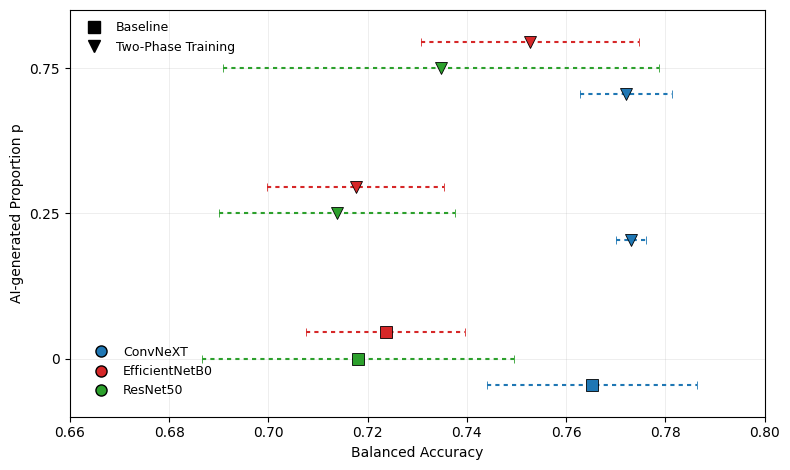

'baseline_vs_gscale5_balanced_accuracy_errorbars.pdf'

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Mean ± std for balanced accuracy only
data = [
    ["convnext_tiny", 0.00, "Baseline", 0.7652, 0.0211],
    ["convnext_tiny", 0.25, "Phase 2",   0.7730, 0.0030],
    ["convnext_tiny", 0.75, "Phase 2",   0.7721, 0.0093],

    ["efficientnet_b0", 0.00, "Baseline", 0.7236, 0.0160],
    ["efficientnet_b0", 0.25, "Phase 2",   0.7176, 0.0178],
    ["efficientnet_b0", 0.75, "Phase 2",   0.7527, 0.0220],

    ["resnet50", 0.00, "Baseline", 0.7181, 0.0314],
    ["resnet50", 0.25, "Phase 2",   0.7138, 0.0238],
    ["resnet50", 0.75, "Phase 2",   0.7348, 0.0440],
]

df = pd.DataFrame(data, columns=["Model", "p", "Phase", "BA", "BA_std"])

model_order = ["convnext_tiny", "resnet50", "efficientnet_b0"]

color_map = {
    "convnext_tiny": "#1f77b4",
    "efficientnet_b0": "#d62728",
    "resnet50": "#2ca02c",
}

marker_map = {
    "Baseline": "s",
    "Phase 2": "v",
}

# Bucket layout
bucket_y = {0.00: 0.0, 0.25: 1.0, 0.75: 2.0}

# Vertical offsets (stacking)
model_offset = {
    "efficientnet_b0": 0.18,
    "resnet50": 0.00,
    "convnext_tiny": -0.18,
}

fig, ax = plt.subplots(figsize=(8, 4.8))

for model in model_order:
    sub = df[df["Model"] == model]

    for _, row in sub.iterrows():
        y = bucket_y[row["p"]] + model_offset[model]

        eb = ax.errorbar(
            row["BA"], y,
            xerr=row["BA_std"],
            fmt=marker_map[row["Phase"]],
            markersize=8,
            markerfacecolor=color_map[model],
            markeredgecolor="black",
            markeredgewidth=0.6,
            ecolor=color_map[model],
            elinewidth=1.5,
            capsize=3,
            zorder=3
        )

        # Make error bars dotted
        for barlinecol in eb[2]:
            barlinecol.set_linestyle((0, (2, 2)))  # dotted

# Labels
# ax.set_title("Baseline vs G.Scale 5: Balanced Accuracy", fontsize=12)
ax.set_xlabel("Balanced Accuracy")
ax.set_ylabel("AI-generated Proportion p")

ax.set_xlim(0.66, 0.80)
ax.set_yticks([0.0, 1.0, 2.0])
ax.set_yticklabels(["0", "0.25", "0.75"])
ax.set_ylim(-0.4, 2.4)

ax.grid(True, alpha=0.3, linewidth=0.5)

# Legends
model_handles = [
    Line2D([0], [0], marker='o', linestyle='None',
           markerfacecolor=color_map["convnext_tiny"], markeredgecolor='black',
           markersize=8, label="ConvNeXT"),
    Line2D([0], [0], marker='o', linestyle='None',
           markerfacecolor=color_map["efficientnet_b0"], markeredgecolor='black',
           markersize=8, label="EfficientNetB0"),
    Line2D([0], [0], marker='o', linestyle='None',
           markerfacecolor=color_map["resnet50"], markeredgecolor='black',
           markersize=8, label="ResNet50"),
]

phase_handles = [
    Line2D([0], [0], marker=marker_map["Baseline"], linestyle='None',
           color='black', markersize=8, label="Baseline"),
    Line2D([0], [0], marker=marker_map["Phase 2"], linestyle='None',
           color='black', markersize=8, label="Two-Phase Training"),
]

leg1 = ax.legend(
    handles=model_handles,
    frameon=False,
    loc="lower left",
    bbox_to_anchor=(0.01, 0.02),
    fontsize=9,
    title_fontsize=9
)
ax.add_artist(leg1)

ax.legend(
    handles=phase_handles,
    frameon=False,
    loc="upper left",
    fontsize=9,
    title_fontsize=9
)

fig.tight_layout()
plt.show()

out_path = "baseline_vs_gscale5_balanced_accuracy_errorbars.pdf"
fig.savefig(out_path, bbox_inches="tight")

out_path